# Aviation Accidents Analysis

You are part of a consulting firm that is tasked to do an analysis of commercial and passenger jet airline safety. The client (an airline/airplane insurer) is interested in knowing what types of aircraft (makes/models) exhibit low rates of total destruction and low likelihood of fatal or serious passenger injuries in the event of an accident. They are also interested in any general variables/conditions that might be at play. Your analysis will be based off of aviation accident data accumulated from the years 1948-2023.

Our client is only interested in airplane makes/models that are professional builds and could potentially still be active. Assume a max lifetime of 40 years for a make/model retirement and make sure to filter your data accordingly (i.e. from 1983 onwards). They would also like separate recommendations for small aircraft vs. larger passenger models. **In addition, make sure that claims that you make are statistically robust and that you have enough samples when making comparisons between groups.**


In this summative assessment you will demonstrate your ability to:
- Use Pandas to load, inspect, and clean the dataset appropriately.
- Transform relevant columns to create measures that address the problem at hand.
- **conduct EDA: visualization and statistical measures to understand the structure of the data**
- **recommend a set of manufacturers to consider as well as specific airplanes conforming to the client's request**
- **discuss the relationship between serious injuries/airplane damage incurred and at least *two* factors at play in the incident. You must provide supporting evidence (visuals, summary statistics, tables) for each claim you make.**

In [ ]:
# loading relevant packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Exploratory Data Analysis  
- Load in the cleaned data

In [ ]:
from google.colab import files

uploaded = files.upload()

df = pd.read_csv(
    next(iter(uploaded)),
    low_memory=False
)

print("Dataset shape:", df.shape)

display(df.head())

df.info()

Saving AviationData_Cleaned.csv to AviationData_Cleaned.csv
Dataset shape: (21447, 27)


,Aircraft.Destroyed,Aircraft.damage,Publication.Date,Injury.Severity,Total.Uninjured,FAR.Description,Registration.Number,Total.Occupants,Model,Location,...,Amateur.Built,Total.Fatal.Injuries,Total.Serious.Injuries,Weather.Condition,Broad.phase.of.flight,Number.of.Engines,Engine.Type,Purpose.of.flight,Fatal.Serious.Injuries,Fatal.Serious.Injury.Rate
0,0.0,Minor,04-12-2014,Incident,588.0,Part 121: Air Carrier,N323EA,588.0,L-1011,"LOS ANGELES, CA",...,No,NaN,NaN,Vmc,Standing,3.0,Turbo Fan,Unknown,0.0,0.0
1,0.0,Minor,04-12-2014,Incident,588.0,Part 129: Foreign,9VSQQ,588.0,747,"LOS ANGELES, CA",...,No,NaN,NaN,Vmc,Taxi,4.0,Turbo Fan,NaN,0.0,0.0
2,1.0,Destroyed,02-05-2011,Fatal(1),NaN,Part 91: General Aviation,N9600W,2.0,PA-28-140,"CROSSVILLE, TN",...,No,1.0,1.0,Imc,Cruise,1.0,Reciprocating,Personal,2.0,1.0
3,NaN,NaN,17-10-2016,Fatal(1),4.0,Part 91: General Aviation,N927BA,5.0,DHC-6,"MCKINNEY, TX",...,No,1.0,NaN,Vmc,Standing,2.0,Turbo Prop,Skydiving,1.0,0.2
4,0.0,Minor,01-02-2016,Incident,289.0,Part 121: Air Carrier,N69NA,289.0,DC-10-10,"NORFOLK, VA",...,No,NaN,NaN,Vmc,Cruise,3.0,Turbo Fan,Unknown,0.0,0.0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21447 entries, 0 to 21446
Data columns (total 27 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Aircraft.Destroyed         20123 non-null  float64
 1   Aircraft.damage            20220 non-null  object 
 2   Publication.Date           20490 non-null  object 
 3   Injury.Severity            20634 non-null  object 
 4   Total.Uninjured            20736 non-null  float64
 5   FAR.Description            20967 non-null  object 
 6   Registration.Number        21241 non-null  object 
 7   Total.Occupants            21400 non-null  float64
 8   Model                      21429 non-null  object 
 9   Location                   21441 non-null  object 
 10  Make                       21444 non-null  object 
 11  Country                    21446 non-null  object 
 12  Aircraft.Category          21447 non-null  object 
 13  Event.Date                 21447 non-null  obj

## Explore safety metrics across models/makes
- Remember that the client is interested in separate recommendations for smaller airplanes and larger airplanes. Choose a passenger threshold of 20 and separate the plane types.

In [ ]:
# Ensure the key columns are numeric
df["Total.Occupants"] = pd.to_numeric(
    df["Total.Occupants"], errors="coerce"
)

df["Fatal.Serious.Injury.Rate"] = pd.to_numeric(
    df["Fatal.Serious.Injury.Rate"], errors="coerce"
)

df["Aircraft.Destroyed"] = pd.to_numeric(
    df["Aircraft.Destroyed"], errors="coerce"
)

# Separate aircraft by number of occupants
df["Aircraft.Size"] = pd.Series(
    pd.NA, index=df.index, dtype="string"
)

df.loc[
    df["Total.Occupants"].between(1, 20),
    "Aircraft.Size"
] = "Small"

df.loc[
    df["Total.Occupants"] > 20,
    "Aircraft.Size"
] = "Large"

# Check the number of records in each group
print("Number of records by aircraft size:")
display(df["Aircraft.Size"].value_counts(dropna=False))

# Compare average injury rates and destruction rates
print("Safety metrics by aircraft size:")
display(
    df.groupby("Aircraft.Size")[
        ["Fatal.Serious.Injury.Rate", "Aircraft.Destroyed"]
    ].mean().round(3)
)

Number of records by aircraft size:


,count
Aircraft.Size,
Small,19555
Large,988
<NA>,904


Safety metrics by aircraft size:


,Fatal.Serious.Injury.Rate,Aircraft.Destroyed
Aircraft.Size,,
Large,0.067,0.119
Small,0.295,0.115


#### Analyzing Makes

Explore the human injury risk profile for small and larger Makes:
- choose the 15 makes for each group possessing the lowest mean fatal/seriously injured fraction
- plot the mean fatal/seriously injured fraction for each of these subgroups side-by-side

15 small-aircraft makes with the lowest average injury fractions:


,Aircraft.Size,Make,mean,count
602,Small,JAVRON,0.0,1
440,Small,FERGUSON WILLIAM C,0.0,1
441,Small,FERNANDES DALE R,0.0,1
875,Small,REMOS,0.0,3
891,Small,ROWE DENNIS A,0.0,1
902,Small,SABRELINER CORP.,0.0,1
905,Small,SANTA FE AIRCRAFT LLC,0.0,1
409,Small,ERIC A MUNZER,0.0,1
907,Small,SC IAR SA BRASOV,0.0,1
908,Small,SCHUMACHER,0.0,1


15 large-aircraft makes with the lowest average injury fractions:


,Aircraft.Size,Make,mean,count
0,Large,737,0.0,2
6,Large,BAE,0.0,4
15,Large,CESSNA,0.0,2
10,Large,BOEING OF CANADA/DEHAV DIV,0.0,1
13,Large,"BOMBARDIER, INC.",0.0,4
14,Large,BRITISH AEROSPACE,0.0,1
21,Large,EMBRAER S.A.,0.0,1
17,Large,DEHAVILLAND,0.0,1
25,Large,GRUMMAN,0.0,1
26,Large,GULFSTREAM,0.0,1


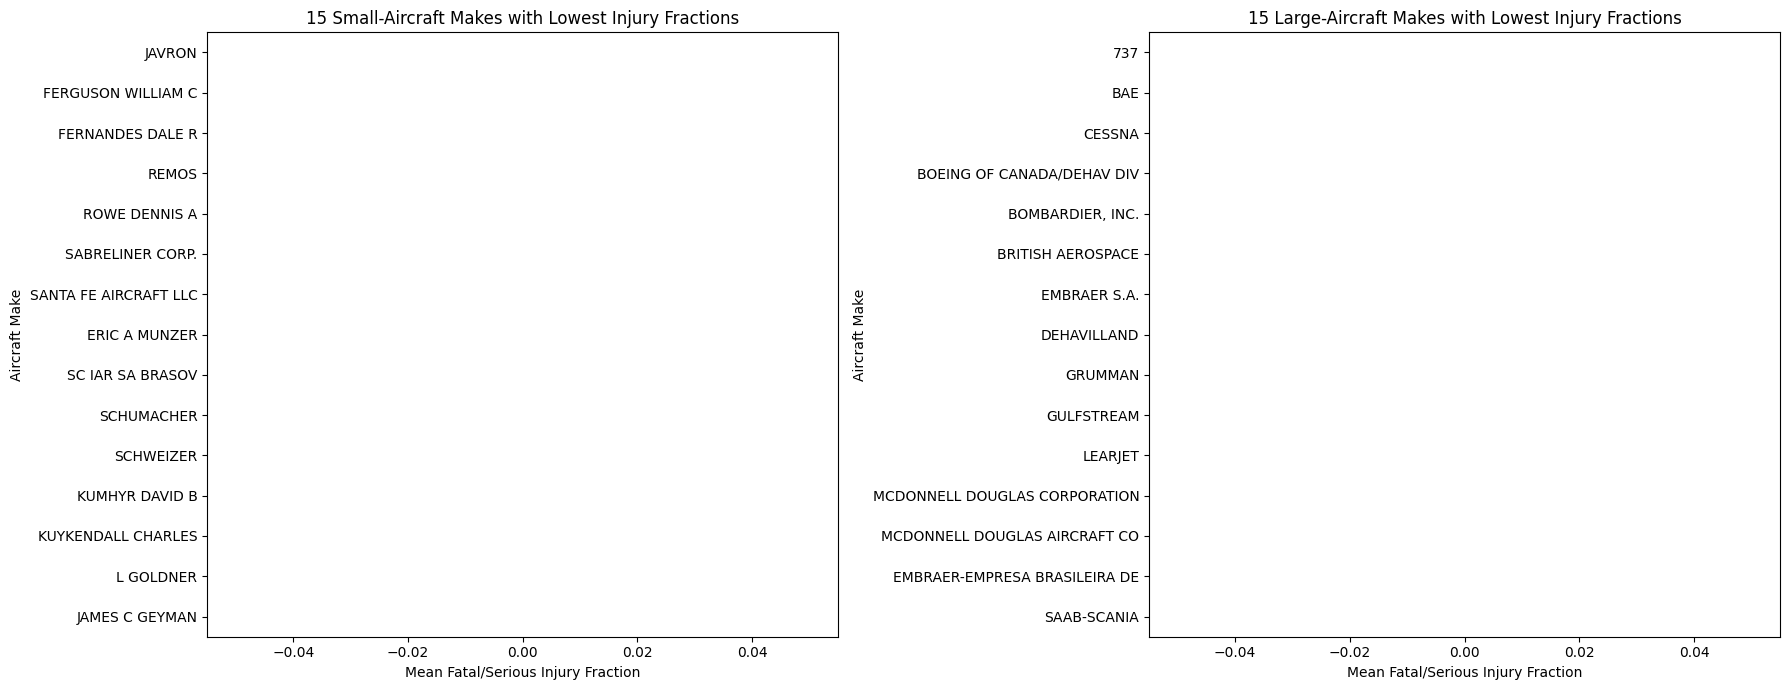

In [ ]:
# Calculate the average injury fraction for each make and aircraft size
make_safety = (
    df.dropna(subset=[
        "Make",
        "Aircraft.Size",
        "Fatal.Serious.Injury.Rate"
    ])
    .groupby(["Aircraft.Size", "Make"])
    ["Fatal.Serious.Injury.Rate"]
    .agg(["mean", "count"])
    .reset_index()
)

# Select the 15 makes with the lowest average injury fraction
small_makes = (
    make_safety[make_safety["Aircraft.Size"] == "Small"]
    .sort_values("mean")
    .head(15)
)

large_makes = (
    make_safety[make_safety["Aircraft.Size"] == "Large"]
    .sort_values("mean")
    .head(15)
)

# Display the results
print("15 small-aircraft makes with the lowest average injury fractions:")
display(small_makes)

print("15 large-aircraft makes with the lowest average injury fractions:")
display(large_makes)

# Plot the two groups side by side
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

sns.barplot(
    data=small_makes,
    x="mean",
    y="Make",
    ax=axes[0]
)
axes[0].set_title("15 Small-Aircraft Makes with Lowest Injury Fractions")
axes[0].set_xlabel("Mean Fatal/Serious Injury Fraction")
axes[0].set_ylabel("Aircraft Make")

sns.barplot(
    data=large_makes,
    x="mean",
    y="Make",
    ax=axes[1]
)
axes[1].set_title("15 Large-Aircraft Makes with Lowest Injury Fractions")
axes[1].set_xlabel("Mean Fatal/Serious Injury Fraction")
axes[1].set_ylabel("Aircraft Make")

plt.tight_layout()
plt.show()

In [ ]:
from google.colab import sheets
sheet = sheets.InteractiveSheet(df=large_makes)

https://docs.google.com/spreadsheets/d/1J1PSgafkFSs98CfnlM7JI2oKKFQ5wL-HL943JgJEsnY/edit#gid=0


In [ ]:
from google.colab import sheets
sheet = sheets.InteractiveSheet(df=small_makes)

https://docs.google.com/spreadsheets/d/1my-Ik16pD1IoNm_5RpsiGW2_kRPB6XZuLdcznjx67Us/edit#gid=0


**Distribution of injury rates: small makes**

Use a violinplot to look at the distribution of the fraction of passengers serious/fatally injured for small airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

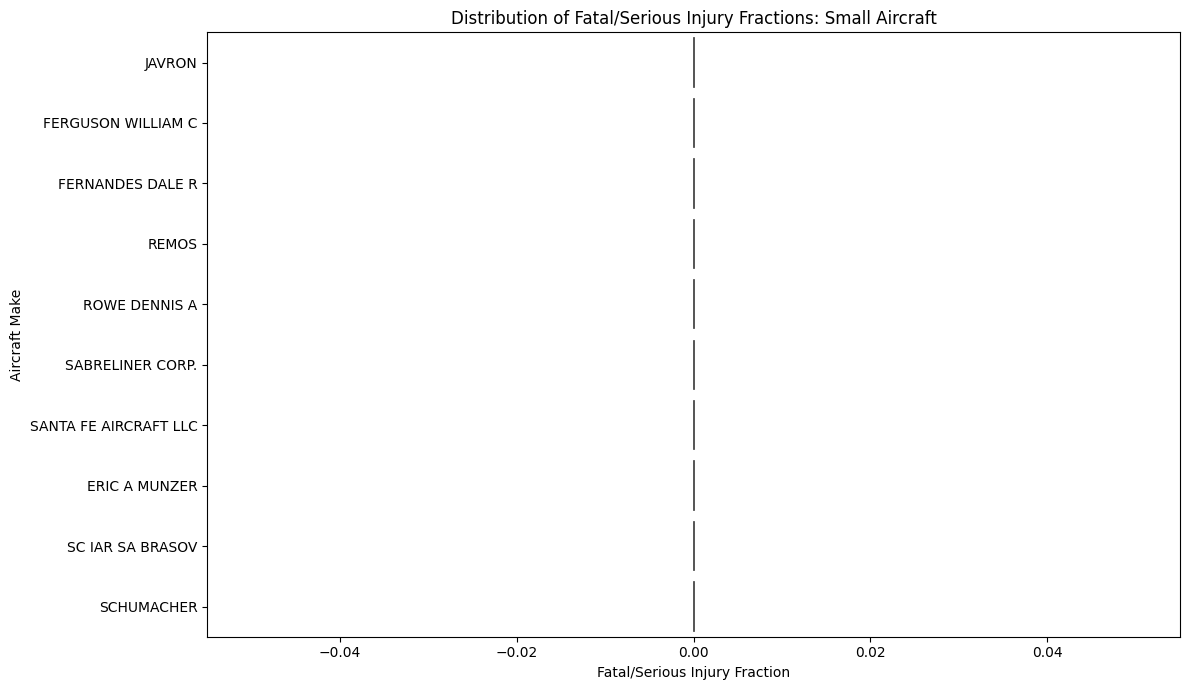

In [ ]:
# Select the 10 small-aircraft makes with the lowest mean injury fractions
small_ten = (
    make_safety[make_safety["Aircraft.Size"] == "Small"]
    .sort_values("mean")
    .head(10)
)

# Keep the accident records for those 10 makes
small_data = df[
    (df["Aircraft.Size"] == "Small") &
    (df["Make"].isin(small_ten["Make"]))
].dropna(subset=["Fatal.Serious.Injury.Rate", "Make"])

# Draw the violin plot
plt.figure(figsize=(12, 7))

sns.violinplot(
    data=small_data,
    x="Fatal.Serious.Injury.Rate",
    y="Make",
    order=small_ten["Make"].tolist(),
    inner="quartile",
    cut=0
)

plt.title("Distribution of Fatal/Serious Injury Fractions: Small Aircraft")
plt.xlabel("Fatal/Serious Injury Fraction")
plt.ylabel("Aircraft Make")
plt.tight_layout()
plt.show()

**Distribution of injury rates: large makes**

Use a stripplot to look at the distribution of the fraction of passengers serious/fatally injured for large airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

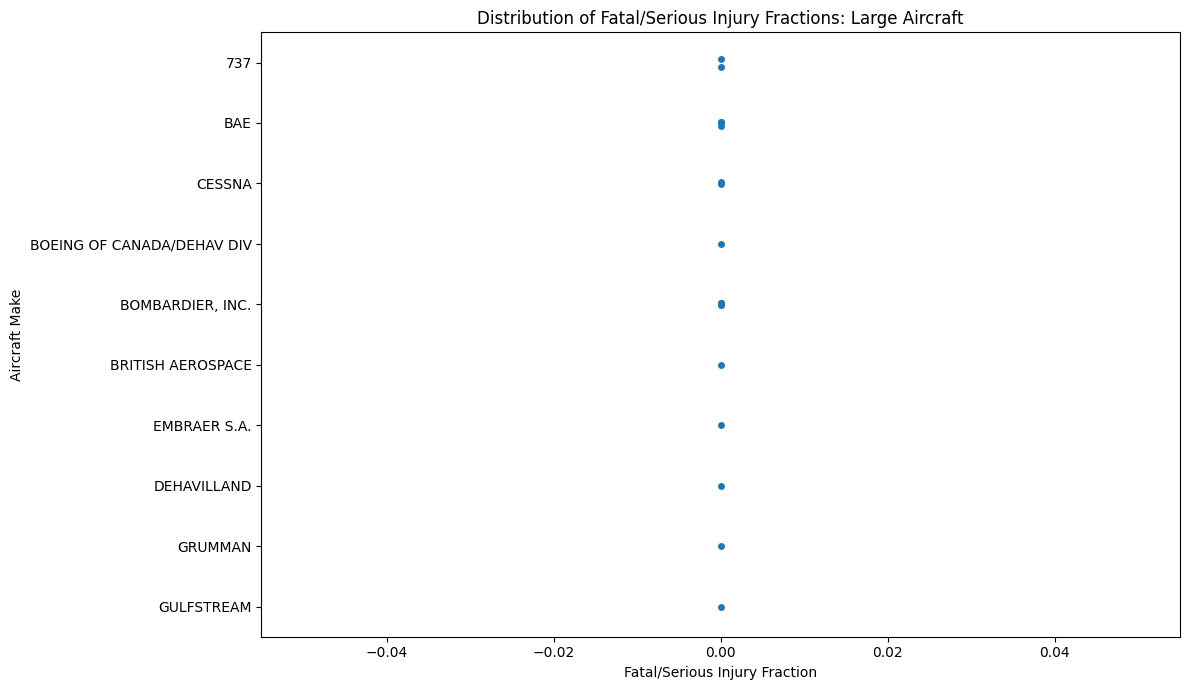

In [ ]:

# Select the 10 large-aircraft makes with the lowest mean injury fractions
large_ten = (
    make_safety[make_safety["Aircraft.Size"] == "Large"]
    .sort_values("mean")
    .head(10)
)

# Keep accident records for those 10 makes
large_data = df[
    (df["Aircraft.Size"] == "Large") &
    (df["Make"].isin(large_ten["Make"]))
].dropna(
    subset=["Fatal.Serious.Injury.Rate", "Make"]
)

# Create the strip plot
plt.figure(figsize=(12, 7))

sns.stripplot(
    data=large_data,
    x="Fatal.Serious.Injury.Rate",
    y="Make",
    order=large_ten["Make"].tolist(),
    jitter=True
)

plt.title("Distribution of Fatal/Serious Injury Fractions: Large Aircraft")
plt.xlabel("Fatal/Serious Injury Fraction")
plt.ylabel("Aircraft Make")
plt.tight_layout()
plt.show()


**Evaluate the rate of aircraft destruction for both small and large aircraft by Make.**

Sort your results and keep the lowest 15.

In [ ]:
# Calculate the average rate of aircraft destruction for each make and aircraft size
destruction_rates = (
    df.dropna(subset=[
        "Make",
        "Aircraft.Size",
        "Aircraft.Destroyed"
    ])
    .groupby(["Aircraft.Size", "Make"])
    ["Aircraft.Destroyed"]
    .agg(["mean", "count"])
    .reset_index()
)

# Select the 15 makes with the lowest average rate of aircraft destruction
small_destruction = (
    destruction_rates[destruction_rates["Aircraft.Size"] == "Small"]
    .sort_values("mean", ascending=True)
    .head(15)
)

large_destruction = (
    destruction_rates[destruction_rates["Aircraft.Size"] == "Large"]
    .sort_values("mean", ascending=True)
    .head(15)
)

print("15 small-aircraft makes with the lowest destruction rates:")
display(small_destruction)

print("\n15 large-aircraft makes with the lowest destruction rates:")
display(large_destruction)

15 small-aircraft makes with the lowest destruction rates:


,Aircraft.Size,Make,mean,count
685,Small,MICHAEL J ROBBINS,0.0,1
672,Small,MCDONNELL-DOUGLAS,0.0,1
673,Small,MCGLAUGHLIN RICHARD,0.0,1
674,Small,MCKENNA GLEN R,0.0,1
675,Small,MCKENZIE JOHN P,0.0,1
676,Small,MCNULTY JOHN S,0.0,1
677,Small,MEDWAY,0.0,1
678,Small,MERIWETHER JON,0.0,1
679,Small,MEUER MARK,0.0,2
680,Small,MEYER FRED J,0.0,1



15 large-aircraft makes with the lowest destruction rates:


,Aircraft.Size,Make,mean,count
0,Large,737,0.000000,2
5,Large,BAE,0.000000,2
11,Large,"BOMBARDIER, INC.",0.000000,2
8,Large,BOEING COMPANY,0.000000,2
12,Large,BRITISH AEROSPACE,0.000000,1
14,Large,DEHAVILLAND,0.000000,1
18,Large,EMBRAER-EMPRESA BRASILEIRA DE,0.000000,1
17,Large,EMBRAER S A,0.000000,1
24,Large,MCDONNELL DOUGLAS AIRCRAFT CO,0.000000,6
25,Large,MCDONNELL DOUGLAS CORPORATION,0.000000,1


In [ ]:
from google.colab import sheets
sheet = sheets.InteractiveSheet(df=large_destruction)

https://docs.google.com/spreadsheets/d/1K-MfmNn3q5tiolDeAZSm1HRdPfypyKEPx3xxxC-s1xE/edit#gid=0


In [ ]:
from google.colab import sheets
sheet = sheets.InteractiveSheet(df=small_destruction)

https://docs.google.com/spreadsheets/d/15yq09MioJxK-XLmHcTYkMNLAQQ1Gjm-j31tCPITC_xQ/edit#gid=0


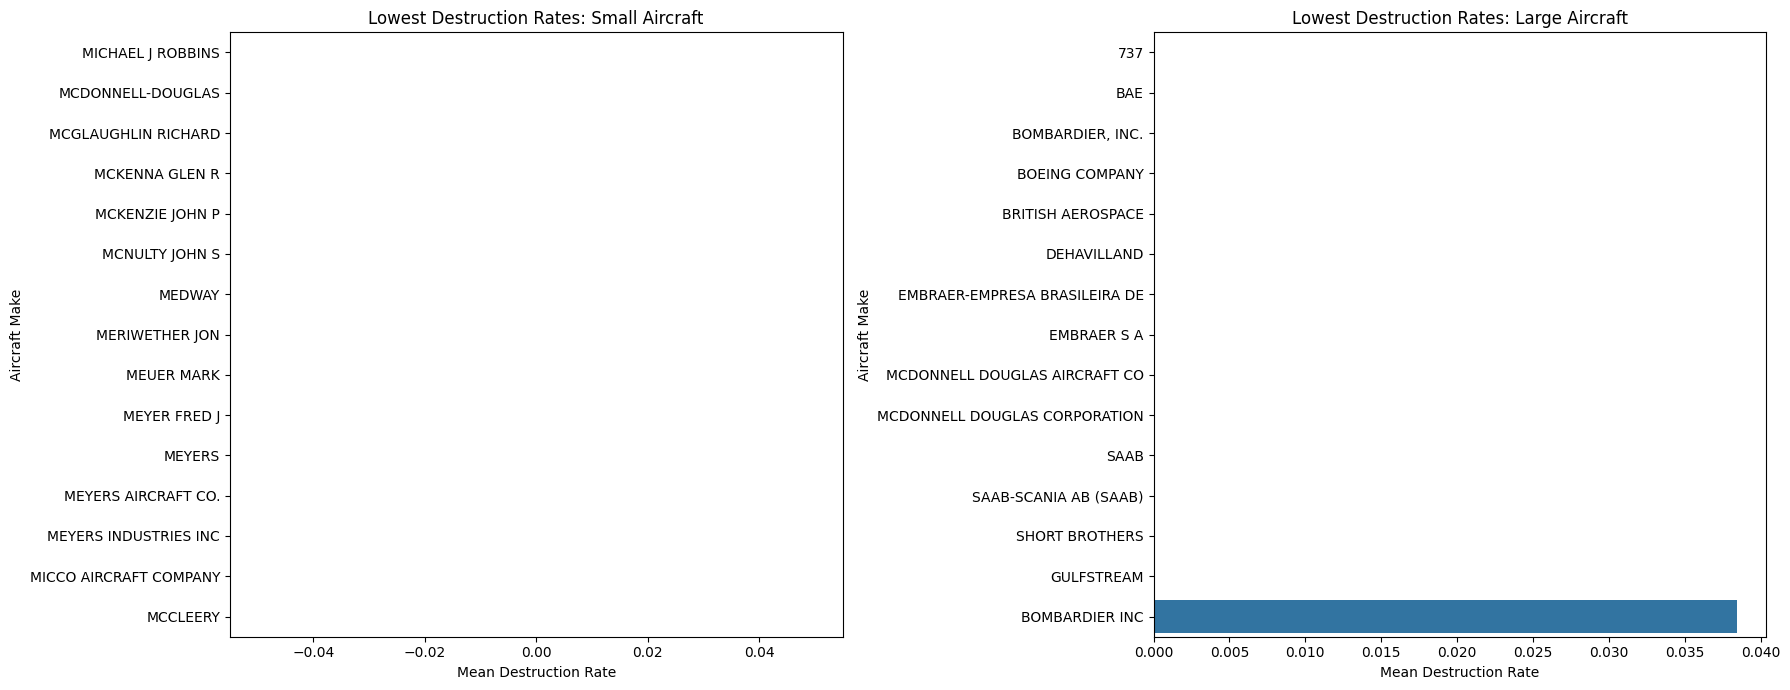

In [ ]:

# Plot the destruction rates for small and large aircraft

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

sns.barplot(
    data=small_destruction,
    x="mean",
    y="Make",
    ax=axes[0]
)
axes[0].set_title("Lowest Destruction Rates: Small Aircraft")
axes[0].set_xlabel("Mean Destruction Rate")
axes[0].set_ylabel("Aircraft Make")

sns.barplot(
    data=large_destruction,
    x="mean",
    y="Make",
    ax=axes[1]
)
axes[1].set_title("Lowest Destruction Rates: Large Aircraft")
axes[1].set_xlabel("Mean Destruction Rate")
axes[1].set_ylabel("Aircraft Make")

plt.tight_layout()
plt.show()


#### Provide a short discussion on your findings for your summary statistics and plots:
- Make any recommendations for Makes here based off of the destroyed fraction and fraction fatally/seriously injured
- Comment on the calculated statistics and any corresponding distributions you have visualized.

Findings and Recommendations

The analysis compared fatal and serious injury fractions and aircraft destruction rates across small and large aircraft makes. The bar charts show the makes with the lowest average injury fractions and the lowest destruction rates among recorded accidents. The violin plot and strip plot help illustrate how injury fractions vary across individual accident records.

Aircraft makes with lower average injury fractions or destruction rates may have better outcomes in the recorded accidents. However, the number of records for each make should also be considered, because makes with few observations may produce misleading averages.

I recommend considering both injury fractions and destruction rates when evaluating aircraft safety. Further analysis should examine aircraft models and other factors, such as weather conditions and phase of flight. Since the dataset contains accident records rather than all flights, these results cannot establish the probability of an accident or injury during normal flight operations.

### Analyze plane types
- plot the mean fatal/seriously injured fraction for both small and larger planes
- also provide a distributional plot of your choice for the fatal/seriously injured fraction by airplane type (stripplot, violin, etc)  
- filter ensuring that you have at least ten individual examples in each model/make to average over

**Larger planes**

Large aircraft types with at least 10 accident records:


,Make,Model,mean,count
181,BOEING,777,0.001,33
146,BOEING,757,0.001,18
197,BOEING,787,0.003,11
119,BOEING,737-7H4,0.003,12
241,BOMBARDIER INC,CL-600-2B19,0.004,14
291,EMBRAER,EMB145,0.009,11
286,EMBRAER,EMB-145LR,0.010,15
134,BOEING,747,0.023,11
160,BOEING,767,0.047,31
97,BOEING,737 7H4,0.068,14


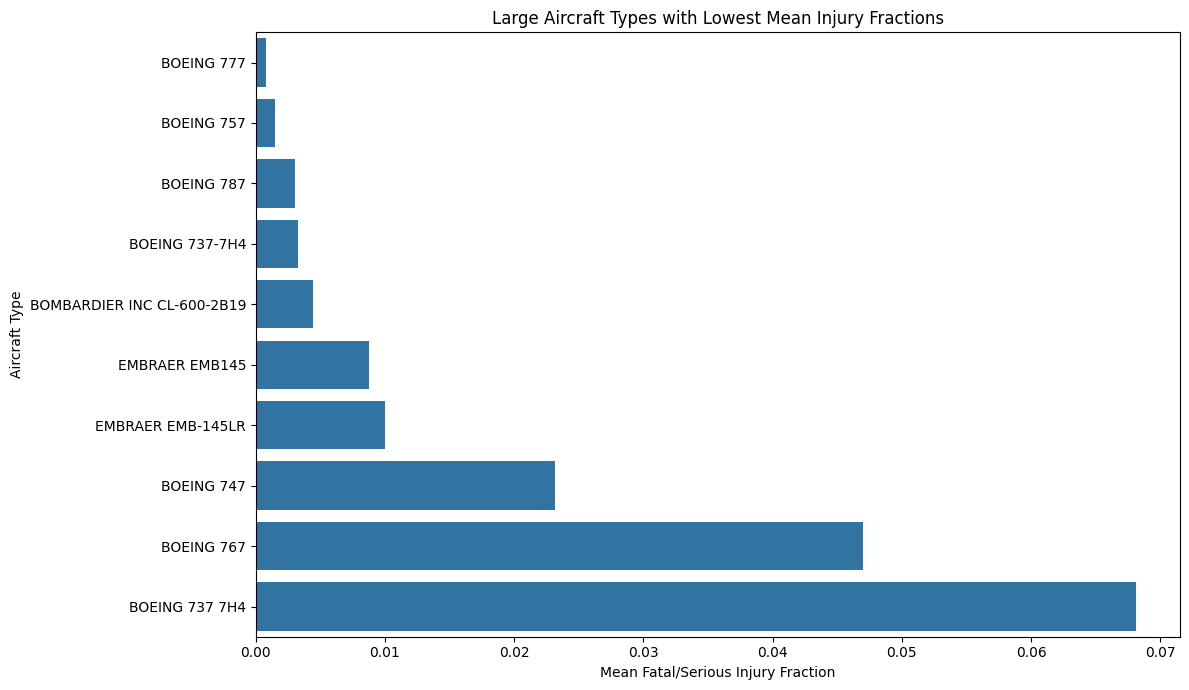

In [ ]:

# Analyze large aircraft by make and model
large_planes = (
    df[df["Aircraft.Size"] == "Large"]
    .dropna(subset=[
        "Make",
        "Model",
        "Fatal.Serious.Injury.Rate"
    ])
    .groupby(["Make", "Model"])["Fatal.Serious.Injury.Rate"]
    .agg(["mean", "count"])
    .reset_index()
)

# Keep aircraft types with at least 10 accident records
large_planes = (
    large_planes[large_planes["count"] >= 10]
    .sort_values("mean")
)

print("Large aircraft types with at least 10 accident records:")
display(large_planes.head(15).round(3))

# Plot the 10 aircraft types with the lowest mean injury fractions
large_top10 = large_planes.head(10).copy()
large_top10["Aircraft Type"] = (
    large_top10["Make"] + " " + large_top10["Model"]
)

plt.figure(figsize=(12, 7))
sns.barplot(
    data=large_top10,
    x="mean",
    y="Aircraft Type"
)
plt.title("Large Aircraft Types with Lowest Mean Injury Fractions")
plt.xlabel("Mean Fatal/Serious Injury Fraction")
plt.ylabel("Aircraft Type")
plt.tight_layout()
plt.show()


**Smaller planes**
- for smaller planes, limit your plotted results to the makes with the 10 lowest mean serious/fatal injury fractions

Small aircraft types with at least 10 accident records:


,Make,Model,mean,count
2467,MAULE,M-5-210C,0.000,11
1006,CESSNA,172SP,0.000,12
1688,DIAMOND AIRCRAFT IND INC,DA 20 C1,0.000,11
3430,SCHWEIZER,G-164B,0.000,10
1028,CESSNA,180J,0.036,28
1183,CESSNA,A185E,0.039,18
2943,PIPER,PA-20,0.040,25
549,BEECH,B19,0.042,16
156,AIR TRACTOR,AT 602,0.042,12
1860,EVEKTOR-AEROTECHNIK AS,SPORTSTAR,0.048,21


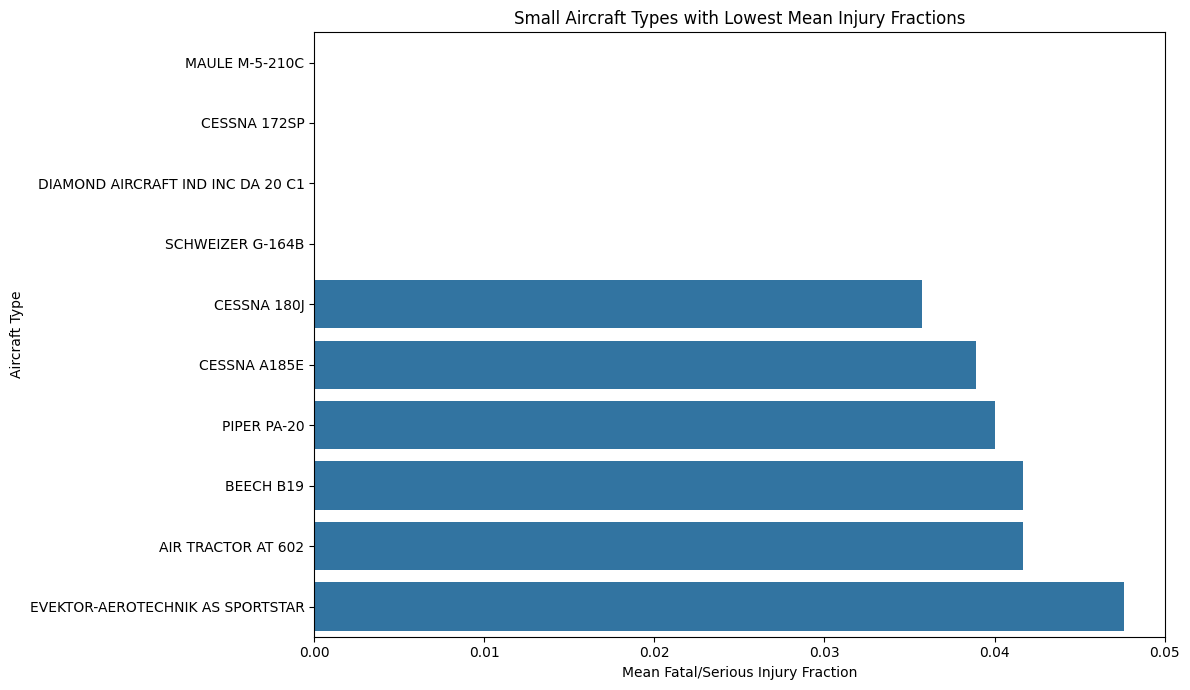

In [ ]:

# Analyze small aircraft by make and model
small_planes = (
    df[df["Aircraft.Size"] == "Small"]
    .dropna(subset=[
        "Make",
        "Model",
        "Fatal.Serious.Injury.Rate"
    ])
    .groupby(["Make", "Model"])["Fatal.Serious.Injury.Rate"]
    .agg(["mean", "count"])
    .reset_index()
)

# Keep aircraft types with at least 10 accident records
small_planes = (
    small_planes[small_planes["count"] >= 10]
    .sort_values("mean")
)

print("Small aircraft types with at least 10 accident records:")
display(small_planes.head(15).round(3))

# Plot the 10 aircraft types with the lowest mean injury fractions
small_top10 = small_planes.head(10).copy()
small_top10["Aircraft Type"] = (
    small_top10["Make"] + " " + small_top10["Model"]
)

plt.figure(figsize=(12, 7))
sns.barplot(
    data=small_top10,
    x="mean",
    y="Aircraft Type"
)
plt.title("Small Aircraft Types with Lowest Mean Injury Fractions")
plt.xlabel("Mean Fatal/Serious Injury Fraction")
plt.ylabel("Aircraft Type")
plt.tight_layout()
plt.show()


### Discussion of Specific Airplane Types
- Discuss what you have found above regarding passenger fraction seriously/ both small and large airplane models.

Final Recommendations

For small aircraft, the analysis identified MAULE M-5-210C, CESSNA 172SP, DIAMOND AIRCRAFT IND INC DA 20 C1, and SCHWEIZER G-164B among the aircraft types with the lowest mean fatal/serious injury fractions. Each had a displayed mean of 0.000 and at least 10 recorded accident cases. Several small-aircraft makes also had mean destruction rates of 0.000 among makes with at least 10 records.

For large aircraft, the BOEING 777 had the lowest mean fatal/serious injury fraction among the aircraft types examined, at 0.000821 across 33 accident records. The BOEING 757 and BOEING 787 also had relatively low mean injury fractions. At the make level, BOMBARDIER INC had the lowest mean destruction rate among the large-aircraft makes with at least 10 records, at approximately 0.038 across 26 records.

These findings identify aircraft types and makes that merit further investigation based on the injury and destruction measures used in this analysis. However, the results should be interpreted cautiously because the number and circumstances of recorded accidents differ across aircraft types. The dataset contains accident records rather than all flights, so it cannot establish the overall probability of an accident or prove that a particular aircraft is safest. Further analysis using flight-hour exposure, accident circumstances, and additional safety data would be needed to make stronger safety recommendations.

### Exploring Other Variables
- Investigate how other variables effect aircraft damage and injury. You must choose **two** factors out of the following but are free to analyze more:

- Weather Condition
- Engine Type
- Number of Engines
- Phase of Flight
- Purpose of Flight

For each factor provide a discussion explaining your analysis with appropriate visualization / data summaries and interpreting your findings.

Injury statistics by weather condition:


,Weather.Condition,mean,median,count
2,Vmc,0.242,0.000,17028
1,Unk,0.436,0.023,258
0,Imc,0.613,1.000,1058


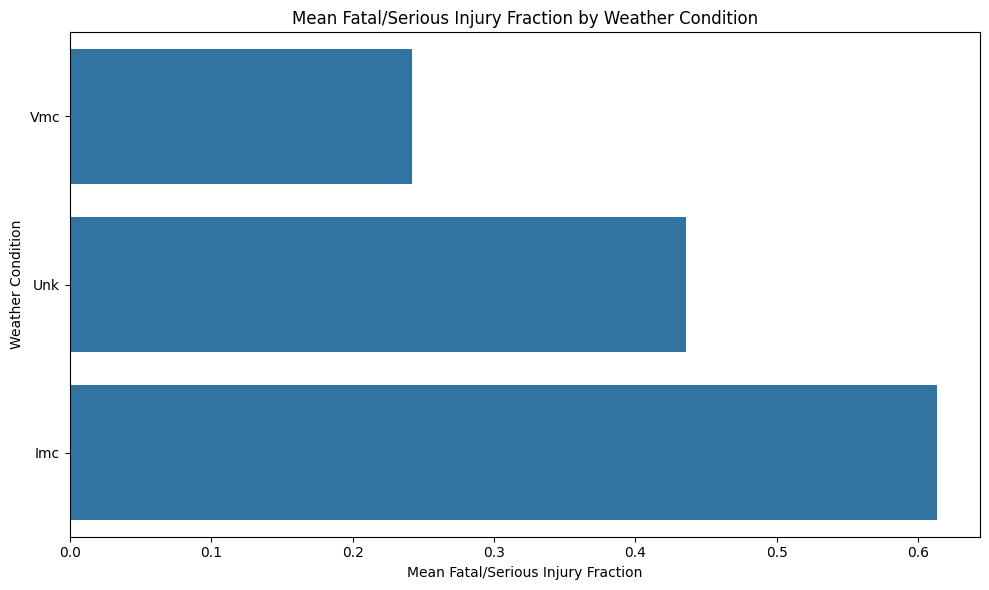

In [ ]:

# Summarize injury fractions by weather condition
weather_summary = (
    df.dropna(
        subset=["Weather.Condition", "Fatal.Serious.Injury.Rate"]
    )
    .groupby("Weather.Condition")["Fatal.Serious.Injury.Rate"]
    .agg(["mean", "median", "count"])
    .reset_index()
    .sort_values("mean")
)

print("Injury statistics by weather condition:")
display(weather_summary.round(3))

# Plot average injury fractions by weather condition
plt.figure(figsize=(10, 6))
sns.barplot(
    data=weather_summary,
    x="mean",
    y="Weather.Condition"
)
plt.title("Mean Fatal/Serious Injury Fraction by Weather Condition")
plt.xlabel("Mean Fatal/Serious Injury Fraction")
plt.ylabel("Weather Condition")
plt.tight_layout()
plt.show()


Injury statistics by phase of flight:


,Broad.phase.of.flight,mean,median,count
5,Landing,0.012,0.0,1255
10,Taxi,0.018,0.0,111
8,Standing,0.094,0.0,46
9,Takeoff,0.111,0.0,509
4,Go-Around,0.113,0.0,89
2,Cruise,0.173,0.0,266
0,Approach,0.219,0.0,234
3,Descent,0.246,0.0,73
1,Climb,0.281,0.0,60
6,Maneuvering,0.355,0.0,169


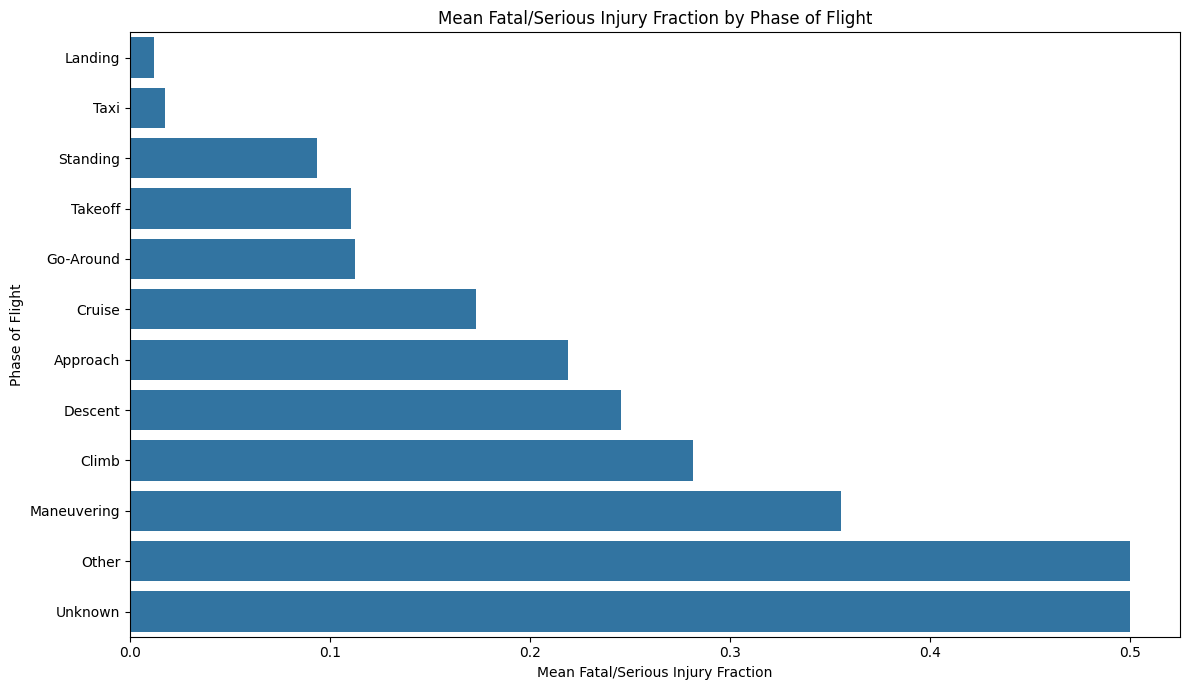

In [ ]:

# Summarize injury fractions by phase of flight
phase_summary = (
    df.dropna(
        subset=["Broad.phase.of.flight", "Fatal.Serious.Injury.Rate"]
    )
    .groupby("Broad.phase.of.flight")["Fatal.Serious.Injury.Rate"]
    .agg(["mean", "median", "count"])
    .reset_index()
    .sort_values("mean")
)

print("Injury statistics by phase of flight:")
display(phase_summary.round(3))

# Plot average injury fractions by phase of flight
plt.figure(figsize=(12, 7))

sns.barplot(
    data=phase_summary,
    x="mean",
    y="Broad.phase.of.flight"
)

plt.title("Mean Fatal/Serious Injury Fraction by Phase of Flight")
plt.xlabel("Mean Fatal/Serious Injury Fraction")
plt.ylabel("Phase of Flight")
plt.tight_layout()
plt.show()


 Findings from Exploring Other Variables

The analysis explored how fatal and serious injury fractions vary across weather conditions and phases of flight in the recorded aviation accidents. The summary tables provide the mean, median, and number of accident records for each category, while the bar charts make it easier to compare average injury fractions.

Differences between categories may indicate that some accident circumstances are associated with more severe injury outcomes than others. However, the number of records in each category should be considered when interpreting the results, and averages may be influenced by extreme observations.

Further investigation could examine additional variables, including engine type, number of engines, and purpose of flight. Because this dataset contains accident records rather than all flights, the findings describe injury outcomes among recorded accidents and cannot establish the overall probability of an accident or prove that a particular factor causes more severe injuries.

In [ ]:
small_top10
large_top10

,Make,Model,mean,count,Aircraft Type
181,BOEING,777,0.000821,33,BOEING 777
146,BOEING,757,0.001473,18,BOEING 757
197,BOEING,787,0.003058,11,BOEING 787
119,BOEING,737-7H4,0.003242,12,BOEING 737-7H4
241,BOMBARDIER INC,CL-600-2B19,0.004431,14,BOMBARDIER INC CL-600-2B19
291,EMBRAER,EMB145,0.008798,11,EMBRAER EMB145
286,EMBRAER,EMB-145LR,0.010000,15,EMBRAER EMB-145LR
134,BOEING,747,0.023161,11,BOEING 747
160,BOEING,767,0.046963,31,BOEING 767
97,BOEING,737 7H4,0.068121,14,BOEING 737 7H4


In [ ]:
small_top10

,Make,Model,mean,count,Aircraft Type
2467,MAULE,M-5-210C,0.000000,11,MAULE M-5-210C
1006,CESSNA,172SP,0.000000,12,CESSNA 172SP
1688,DIAMOND AIRCRAFT IND INC,DA 20 C1,0.000000,11,DIAMOND AIRCRAFT IND INC DA 20 C1
3430,SCHWEIZER,G-164B,0.000000,10,SCHWEIZER G-164B
1028,CESSNA,180J,0.035714,28,CESSNA 180J
1183,CESSNA,A185E,0.038889,18,CESSNA A185E
2943,PIPER,PA-20,0.040000,25,PIPER PA-20
549,BEECH,B19,0.041667,16,BEECH B19
156,AIR TRACTOR,AT 602,0.041667,12,AIR TRACTOR AT 602
1860,EVEKTOR-AEROTECHNIK AS,SPORTSTAR,0.047619,21,EVEKTOR-AEROTECHNIK AS SPORTSTAR


In [ ]:

# 1. Small aircraft types
print("SMALL AIRCRAFT TYPES")
display(small_top10[["Make", "Model", "mean", "count"]].round(3))

# 2. Small aircraft destruction rates
print("SMALL AIRCRAFT DESTRUCTION RATES")
display(small_destruction[["Make", "mean", "count"]].round(3))

# 3. Large aircraft destruction rates
print("LARGE AIRCRAFT DESTRUCTION RATES")
display(large_destruction[["Make", "mean", "count"]].round(3))


SMALL AIRCRAFT TYPES


,Make,Model,mean,count
2467,MAULE,M-5-210C,0.000,11
1006,CESSNA,172SP,0.000,12
1688,DIAMOND AIRCRAFT IND INC,DA 20 C1,0.000,11
3430,SCHWEIZER,G-164B,0.000,10
1028,CESSNA,180J,0.036,28
1183,CESSNA,A185E,0.039,18
2943,PIPER,PA-20,0.040,25
549,BEECH,B19,0.042,16
156,AIR TRACTOR,AT 602,0.042,12
1860,EVEKTOR-AEROTECHNIK AS,SPORTSTAR,0.048,21


SMALL AIRCRAFT DESTRUCTION RATES


,Make,mean,count
685,MICHAEL J ROBBINS,0.0,1
672,MCDONNELL-DOUGLAS,0.0,1
673,MCGLAUGHLIN RICHARD,0.0,1
674,MCKENNA GLEN R,0.0,1
675,MCKENZIE JOHN P,0.0,1
676,MCNULTY JOHN S,0.0,1
677,MEDWAY,0.0,1
678,MERIWETHER JON,0.0,1
679,MEUER MARK,0.0,2
680,MEYER FRED J,0.0,1


LARGE AIRCRAFT DESTRUCTION RATES


,Make,mean,count
0,737,0.000,2
5,BAE,0.000,2
11,"BOMBARDIER, INC.",0.000,2
8,BOEING COMPANY,0.000,2
12,BRITISH AEROSPACE,0.000,1
14,DEHAVILLAND,0.000,1
18,EMBRAER-EMPRESA BRASILEIRA DE,0.000,1
17,EMBRAER S A,0.000,1
24,MCDONNELL DOUGLAS AIRCRAFT CO,0.000,6
25,MCDONNELL DOUGLAS CORPORATION,0.000,1


In [ ]:

# Small-aircraft makes with at least 10 records
small_destruction_reliable = (
    destruction_rates[
        destruction_rates["Aircraft.Size"] == "Small"
    ]
    .query("count >= 10")
    .sort_values("mean")
    .head(15)
)

print("Small-aircraft makes with at least 10 records:")
display(small_destruction_reliable.round(3))

# Large-aircraft makes with at least 10 records
large_destruction_reliable = (
    destruction_rates[
        destruction_rates["Aircraft.Size"] == "Large"
    ]
    .query("count >= 10")
    .sort_values("mean")
    .head(15)
)

print("Large-aircraft makes with at least 10 records:")
display(large_destruction_reliable.round(3))


Small-aircraft makes with at least 10 records:


,Aircraft.Size,Make,mean,count
116,Small,AMERICAN LEGEND AIRCRAFT CO,0.0,17
108,Small,AMERICAN CHAMPION (ACAC),0.0,12
263,Small,CHRISTEN INDUSTRIES INC,0.0,16
489,Small,GREAT LAKES,0.0,19
308,Small,CUB CRAFTERS,0.0,17
309,Small,CUB CRAFTERS INC,0.0,20
313,Small,CUBCRAFTERS INC,0.0,21
289,Small,CONSOLIDATED AERONAUTICS INC.,0.0,16
409,Small,EVEKTOR-AEROTECHNIK AS,0.0,30
913,Small,SIAI-MARCHETTI,0.0,13


Large-aircraft makes with at least 10 records:


,Aircraft.Size,Make,mean,count
10,Large,BOMBARDIER INC,0.038,26
9,Large,BOMBARDIER,0.056,18
16,Large,EMBRAER,0.089,45
7,Large,BOEING,0.097,279
23,Large,MCDONNELL DOUGLAS,0.111,36
2,Large,AIRBUS INDUSTRIE,0.150,20
1,Large,AIRBUS,0.170,53


In [ ]:
display(small_top10[["Make", "Model", "mean", "count"]].round(6))

,Make,Model,mean,count
2467,MAULE,M-5-210C,0.000000,11
1006,CESSNA,172SP,0.000000,12
1688,DIAMOND AIRCRAFT IND INC,DA 20 C1,0.000000,11
3430,SCHWEIZER,G-164B,0.000000,10
1028,CESSNA,180J,0.035714,28
1183,CESSNA,A185E,0.038889,18
2943,PIPER,PA-20,0.040000,25
549,BEECH,B19,0.041667,16
156,AIR TRACTOR,AT 602,0.041667,12
1860,EVEKTOR-AEROTECHNIK AS,SPORTSTAR,0.047619,21
